Mito vs Mito Viability — DBSCAN Clustering (per dataset)

EPS is auto-detected per dataset from the k-distance elbow (second-derivative peak).

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import umap
import pubchempy as pcp

BASE     = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
RESULTS  = BASE + 'results/mito_viability_comparisons/'
ENCODING = 'latin1'

DATASETS = [
    ('Mito Active / Viability Active',   'mito_and_mito_viability_active.csv'),
    ('Mito Active / Viability Inactive', 'mito_active_and_mito_viability_inctive.csv'),
    ('Mito Inactive / Viability Active', 'mito_inactive_and_viability_active.csv'),
    ('Both Inactive',                    'mito_inactive_and_mito_viability_inactive.csv'),
]

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# ── Fingerprint helpers ──────────────────────────────────────────────────────
def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    mat = np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)
    return fps, mat

def _formal_name(raw: str) -> str:
    """Normalise a PubChem compound name to consistent title case.

    Handles ALL-CAPS strings (e.g. 'TAMOXIFEN') and all-lowercase strings
    (e.g. 'tamoxifen') uniformly → 'Tamoxifen'.
    """
    return raw.strip().lower().title()

# ── UMAP helper ──────────────────────────────────────────────────────────────
def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(9, 7))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=60, edgecolors='black', linewidths=0.4, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

# ── k-NN distance plot on 2D UMAP coords (Euclidean) ─────────────────────────
def knn_eps_plot(emb, min_samples, title):
    nbrs = NearestNeighbors(n_neighbors=min_samples + 1).fit(emb)
    distances, _ = nbrs.kneighbors(emb)
    sorted_d = np.sort(distances[:, -1])[::-1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(sorted_d, 'b-', linewidth=1.5)
    ax.set_xlabel('Points sorted by decreasing distance')
    ax.set_ylabel(f'Euclidean dist to {min_samples}-th NN (UMAP space)')
    ax.set_title(f'{title}\nSelect eps at the knee  (min_samples={min_samples})')
    ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'  Min={sorted_d.min():.4f}  Median={np.median(sorted_d):.4f}  Max={sorted_d.max():.4f}')
    return sorted_d

# ── MCS core ─────────────────────────────────────────────────────────────────
def get_mcs_core(mols):
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                         completeRingsOnly=True, timeout=10)
    if mcs and mcs.numAtoms >= 3:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

# ── Draw cluster reps + MCS core ─────────────────────────────────────────────
def draw_cluster_reps(dataset, title, mols_per_row=5, img_size=(280, 230),
                      max_per_cluster=12):
    from IPython.display import display
    reps, legs, highlights = [], [], []
    cl_name_map = {}
    print(f'Fetching PubChem names — {title}...')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub  = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps  = sub['fp'].tolist()
        avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep  = sub.loc[int(np.argmax(avg))]
        cid  = int(rep['PUBCHEM_CID'])
        try:
            c_   = pcp.Compound.from_cid(cid)
            syns = c_.synonyms or []
            short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
            raw   = short[0] if short else (syns[0][:28] if syns else str(cid))
        except Exception:
            raw = str(cid)
        name = _formal_name(raw)
        cl_name_map[cl] = name
        cluster_mols = sub.head(max_per_cluster)['mol'].tolist()
        core = get_mcs_core(cluster_mols)
        if core is not None:
            reps.append(core); legs.append(f'C{cl} (n={len(sub)}) ★ Core ★'); highlights.append([])
        reps.append(rep['mol'])
        match = rep['mol'].GetSubstructMatch(core) if core is not None else []
        legs.append(f'C{cl} (n={len(sub)})\n{name} [CID {cid}]')
        highlights.append(list(match))
        print(f'  Cluster {cl:2d} (n={len(sub):4d})  {name}  [CID {cid}]')
    if not reps:
        print('  No clusters found — all compounds are structurally unique.')
        return cl_name_map
    img = Draw.MolsToGridImage(reps, molsPerRow=mols_per_row, subImgSize=img_size,
                               legends=legs, highlightAtomLists=highlights, returnPNG=False)
    display(img)
    return cl_name_map

# ── UMAP coloured by cluster ──────────────────────────────────────────────────
def umap_by_cluster(dataset, cl_name_map, title):
    fig, ax = plt.subplots(figsize=(12, 8))
    cmap  = plt.cm.tab10
    noise = dataset[dataset['cluster'] == -1]
    if len(noise):
        ax.scatter(noise['umap_x'], noise['umap_y'], c='#cccccc',
                   s=30, edgecolors='none', alpha=0.5,
                   label=f'Unique / Noise (n={len(noise)})')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub  = dataset[dataset['cluster'] == cl]
        name = cl_name_map.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=60, edgecolors='black', linewidths=0.4, alpha=0.85,
                   label=f'Cluster {cl}: {name} (n={len(sub)})')
    for _, row in dataset.iterrows():
        ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=15,
              framealpha=0.95, borderaxespad=0)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout()
    plt.show()

print('Setup complete.')


Setup complete.


  Mito Active / Viability Active
Unique CIDs: 292
Valid molecules: 292


[19:44:50] WARNING: not removing hydrogen atom without neighbors
[19:44:50] WARNING: not removing hydrogen atom without neighbors


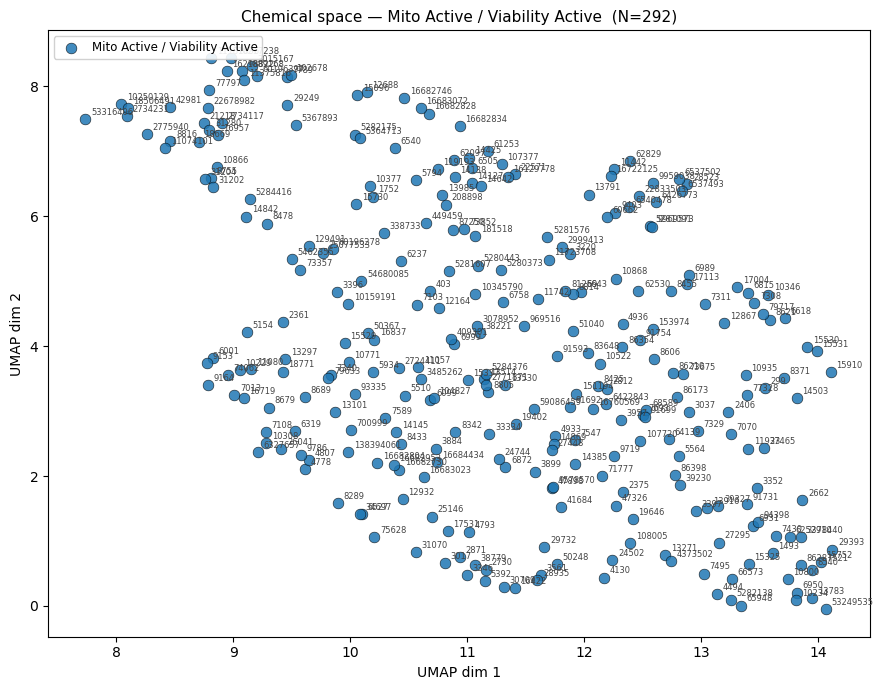

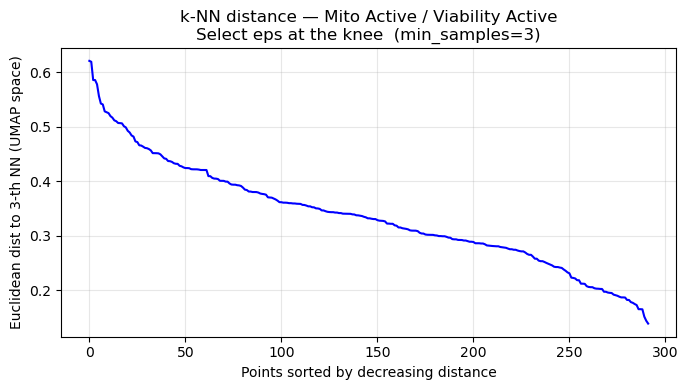

  Min=0.1389  Median=0.3318  Max=0.6204

DBSCAN (eps=0.45, min_samples=3)  →  8 clusters,  2 noise (0.7%)
           Count
Cluster 0    203
Cluster 4     33
Cluster 1     22
Cluster 5     15
Cluster 6      6
Cluster 7      5
Cluster 2      3
Cluster 3      3
Noise          2
Fetching PubChem names — Mito Active / Viability Active...
  Cluster  0 (n= 203)  Chlorosalicylanilide  [CID 14869]
  Cluster  1 (n=  22)  Hexyl 4-Hydroxybenzoate  [CID 14127]
  Cluster  2 (n=   3)  Bromadiolone  [CID 54680085]
  Cluster  3 (n=   3)  Emulphor  [CID 5364713]
  Cluster  4 (n=  33)  Didecyldimonium Bromide  [CID 16957]
  Cluster  5 (n=  15)  Estradiol Valerate  [CID 13791]
  Cluster  6 (n=   6)  Tributyltin Oxide  [CID 16682746]
  Cluster  7 (n=   5)  Ncgc00094807-01  [CID 60196278]


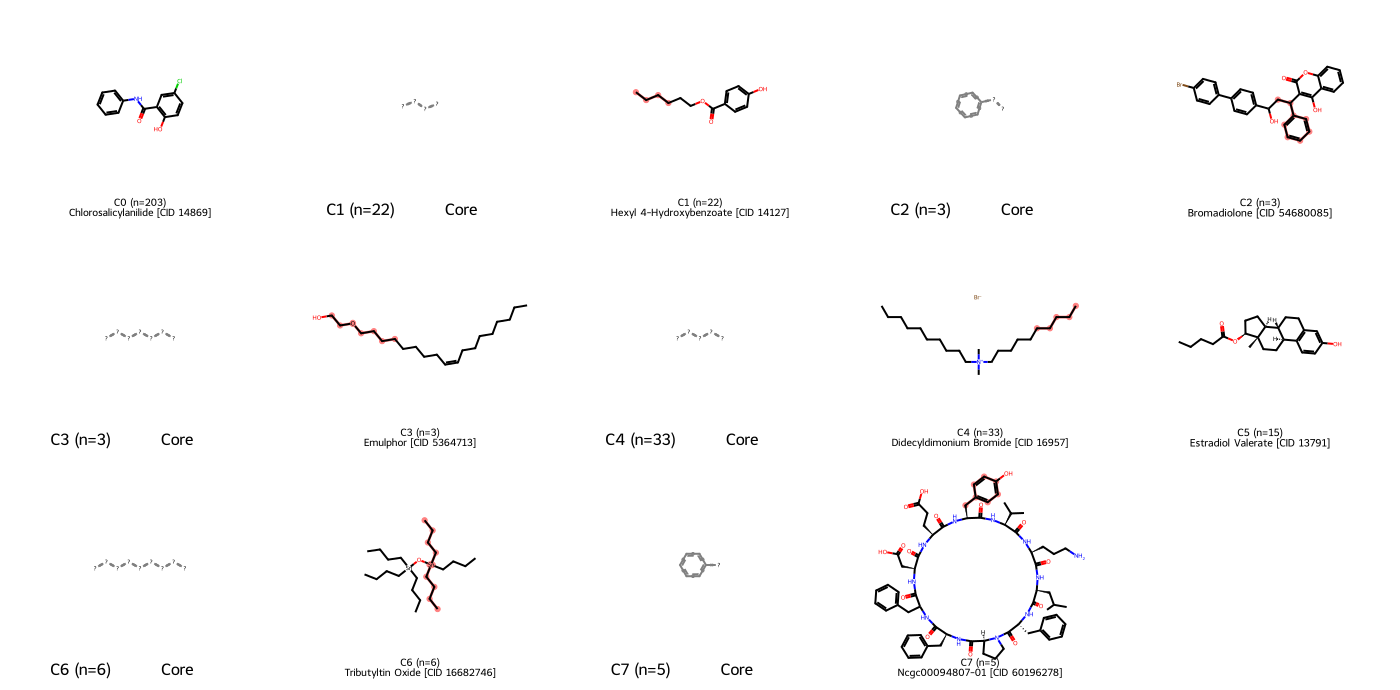

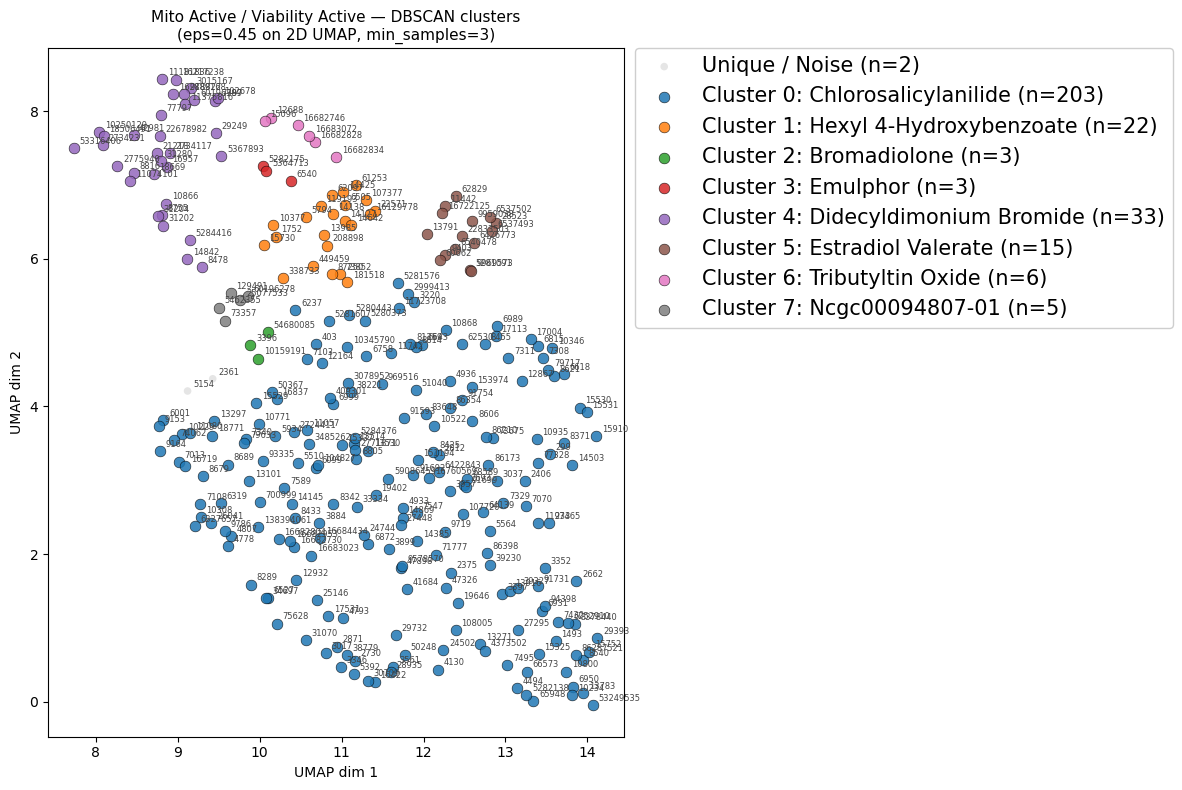

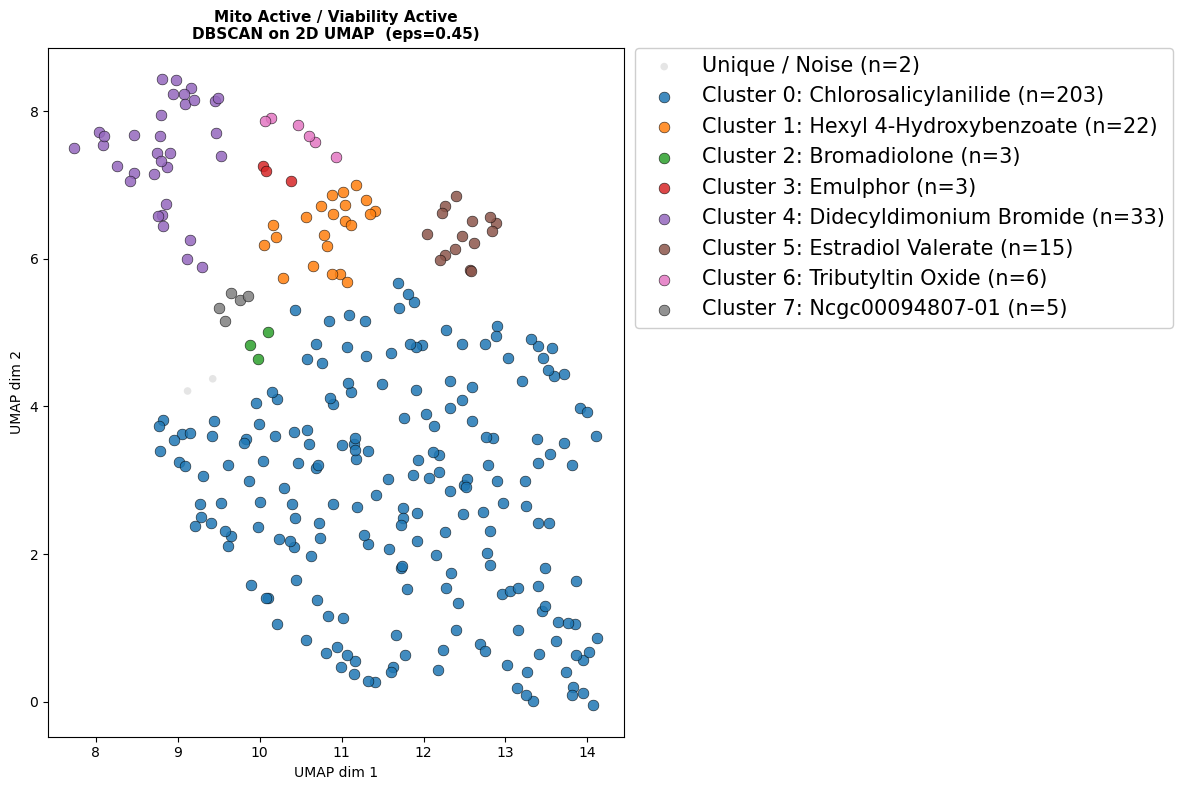

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/mito_viability_comparisons/umap_dbscan_mito_and_mito_viability_active.png

  Mito Active / Viability Inactive
Unique CIDs: 680
Valid molecules: 680


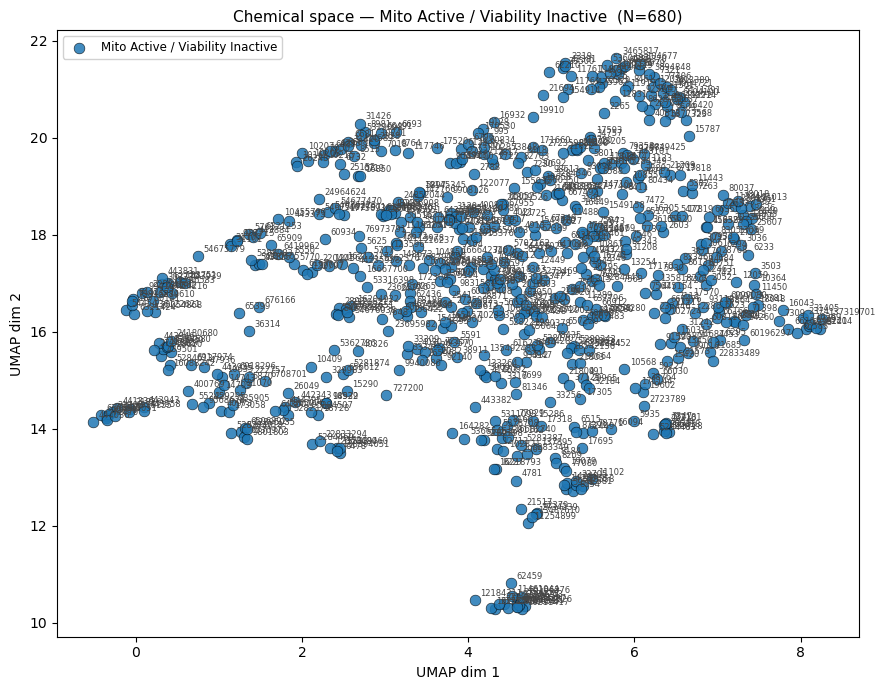

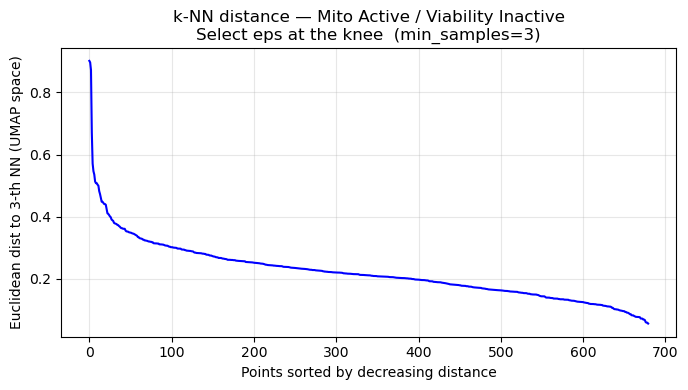

  Min=0.0565  Median=0.2118  Max=0.9016

DBSCAN (eps=0.45, min_samples=3)  →  9 clusters,  3 noise (0.4%)
           Count
Cluster 0    514
Cluster 2     51
Cluster 1     49
Cluster 6     18
Cluster 7     17
Cluster 5     13
Cluster 3      7
Cluster 4      5
Noise          3
Cluster 8      3
Fetching PubChem names — Mito Active / Viability Inactive...
  Cluster  0 (n= 514)  Dioxybenzone  [CID 8569]
  Cluster  1 (n=  49)  Benzenamine, 2,4-Dinitro-  [CID 7321]
  Cluster  2 (n=  51)  Digitoxin  [CID 441207]
  Cluster  3 (n=   7)  Endrin  [CID 12358480]
  Cluster  4 (n=   5)  Tetradecylpyridinium Bromide  [CID 62379]
  Cluster  5 (n=  13)  Betamethasone Dipropionate  [CID 21800]
  Cluster  6 (n=  18)  Daunorubicin  [CID 30323]
  Cluster  7 (n=  17)  Dtxsid5047873  [CID 2734223]
  Cluster  8 (n=   3)  Triciribine  [CID 65399]


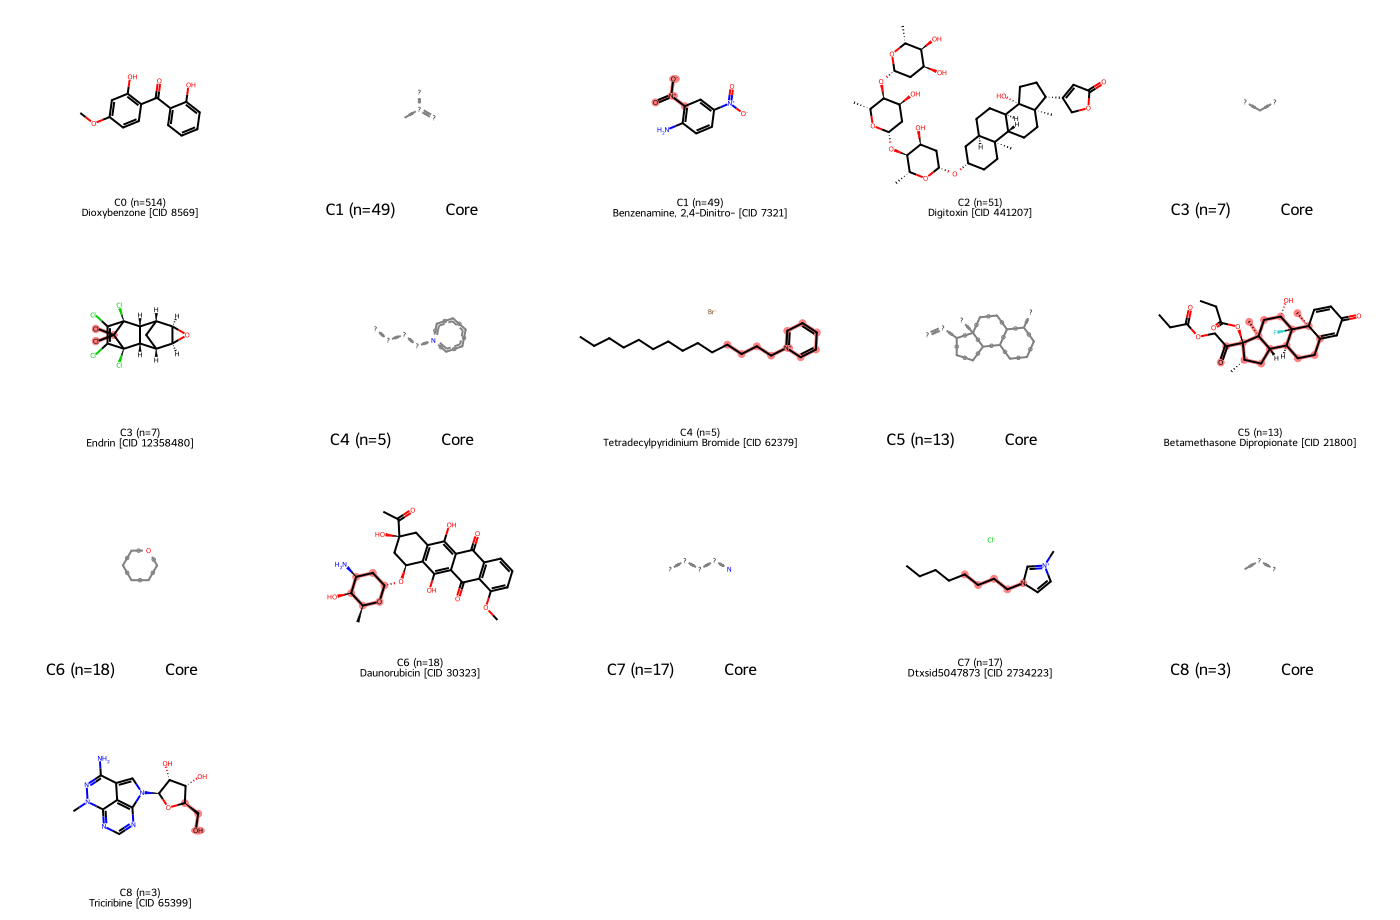

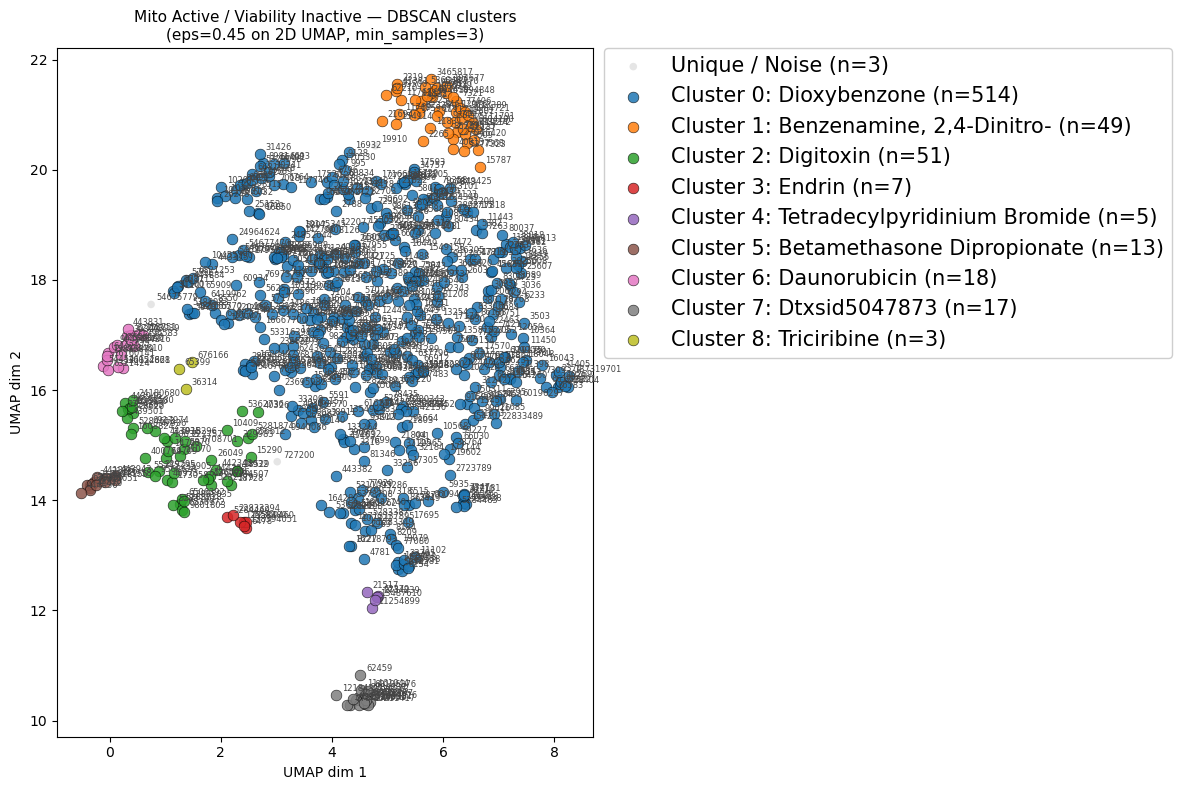

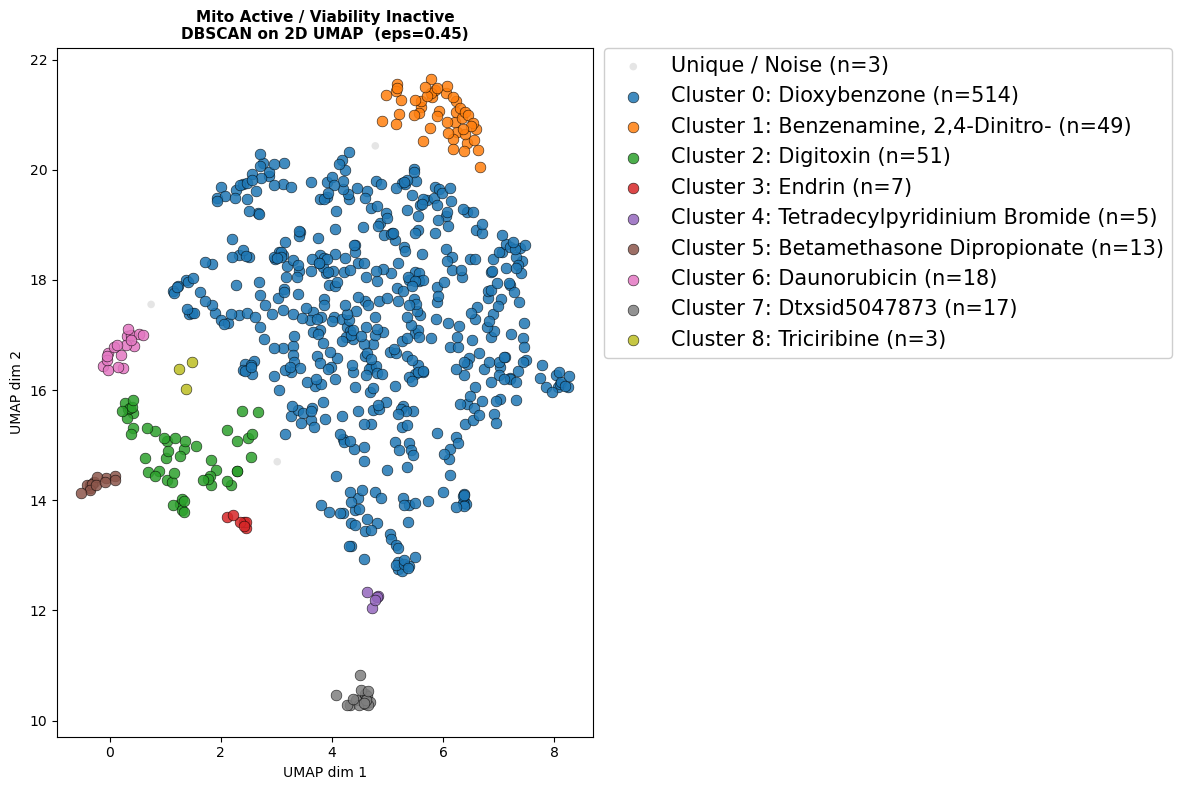

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/mito_viability_comparisons/umap_dbscan_mito_active_and_mito_viability_inctive.png

  Mito Inactive / Viability Active
Unique CIDs: 0
Valid molecules: 0
Too few molecules — skipping.

  Both Inactive
Unique CIDs: 3196


[19:45:05] WARNING: not removing hydrogen atom without neighbors


Valid molecules: 3196


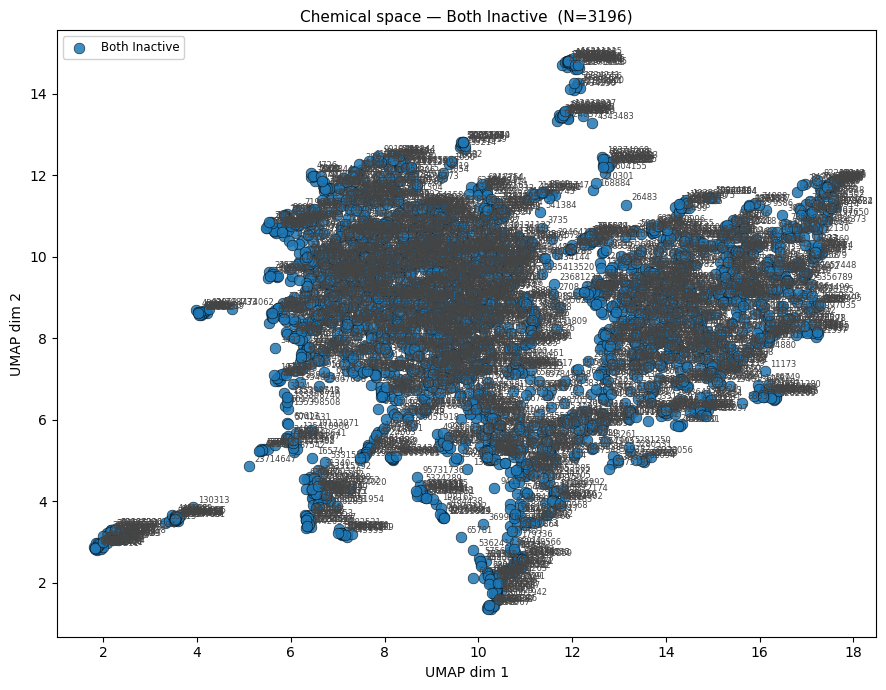

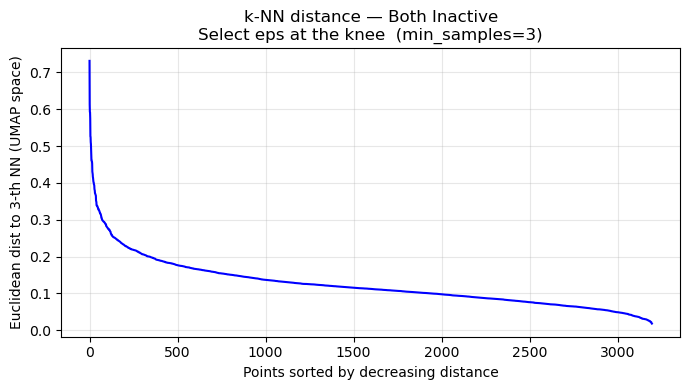

  Min=0.0179  Median=0.1121  Max=0.7314

DBSCAN (eps=0.45, min_samples=3)  →  13 clusters,  3 noise (0.1%)
            Count
Cluster 0    2954
Cluster 3      42
Cluster 11     32
Cluster 4      25
Cluster 10     25
Cluster 5      20
Cluster 7      20
Cluster 8      20
Cluster 2      17
Cluster 1      15
Cluster 6      12
Cluster 12      7
Cluster 9       4
Noise           3
Fetching PubChem names — Both Inactive...
  Cluster  0 (n=2954)  Ethyl Benzoate  [CID 7165]
  Cluster  1 (n=  15)  C24H34N8O4S2  [CID 3085168]
  Cluster  2 (n=  17)  Gatifloxacin  [CID 5379]
  Cluster  3 (n=  42)  Cefotaxime Sodium  [CID 10695961]
  Cluster  4 (n=  25)  Neryl Acetate  [CID 1549025]
  Cluster  5 (n=  20)  Metampicillin Sodium  [CID 25195407]
  Cluster  6 (n=  12)  Midecamycin  [CID 5282169]
  Cluster  7 (n=  20)  Bpmbf4  [CID 2734180]
  Cluster  8 (n=  20)  Dtxsid4049375  [CID 11009532]
  Cluster  9 (n=   4)  Iron(3+) Trichloride  [CID 166033]
  Cluster 10 (n=  25)  Codeine Hydrochloride  [CID 159840

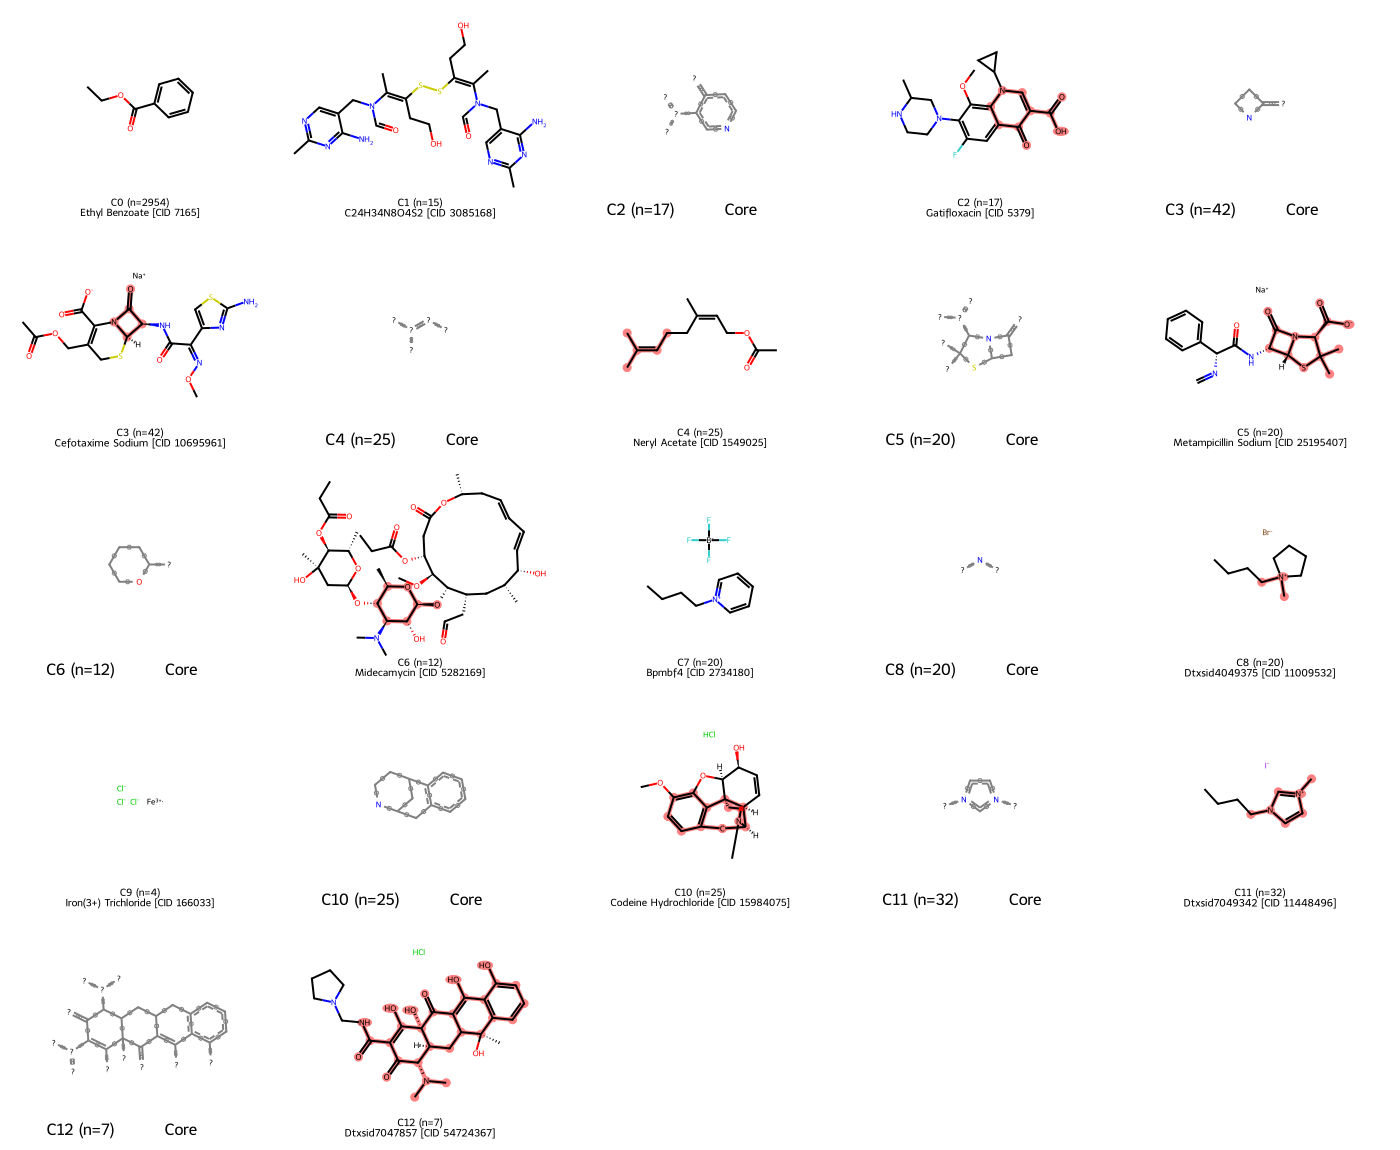

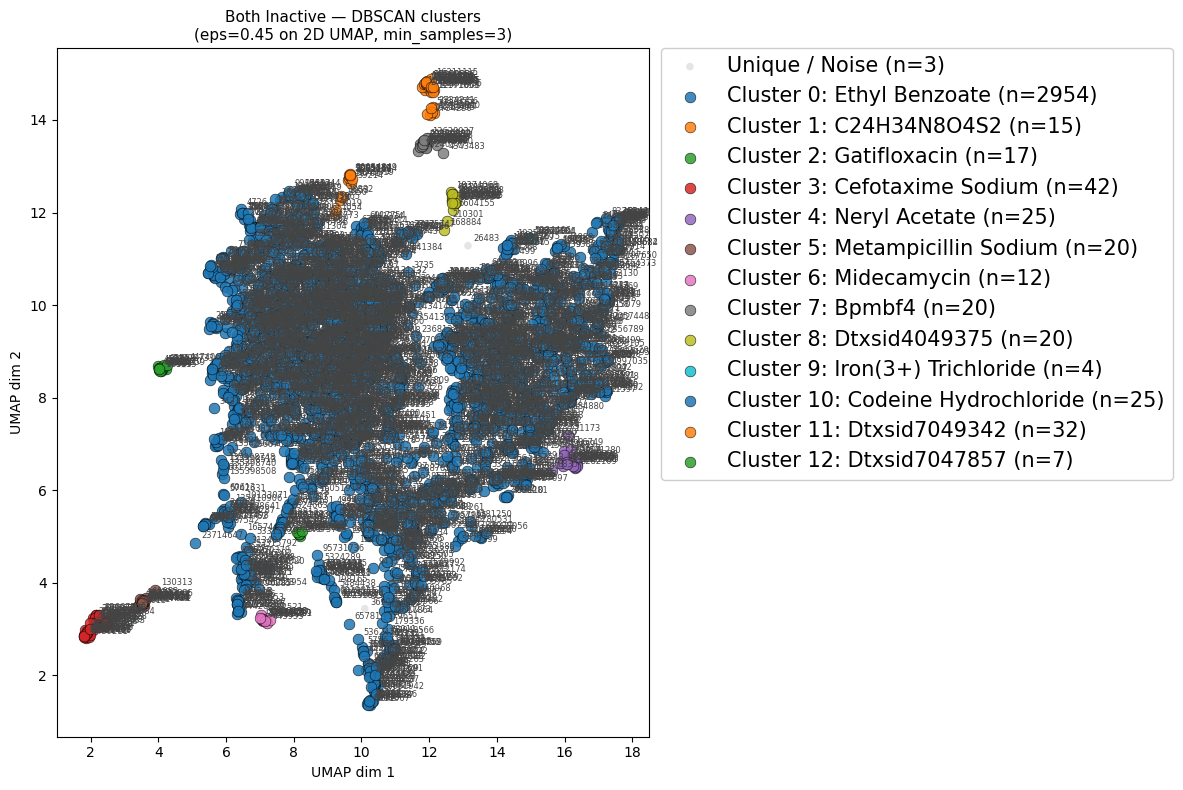

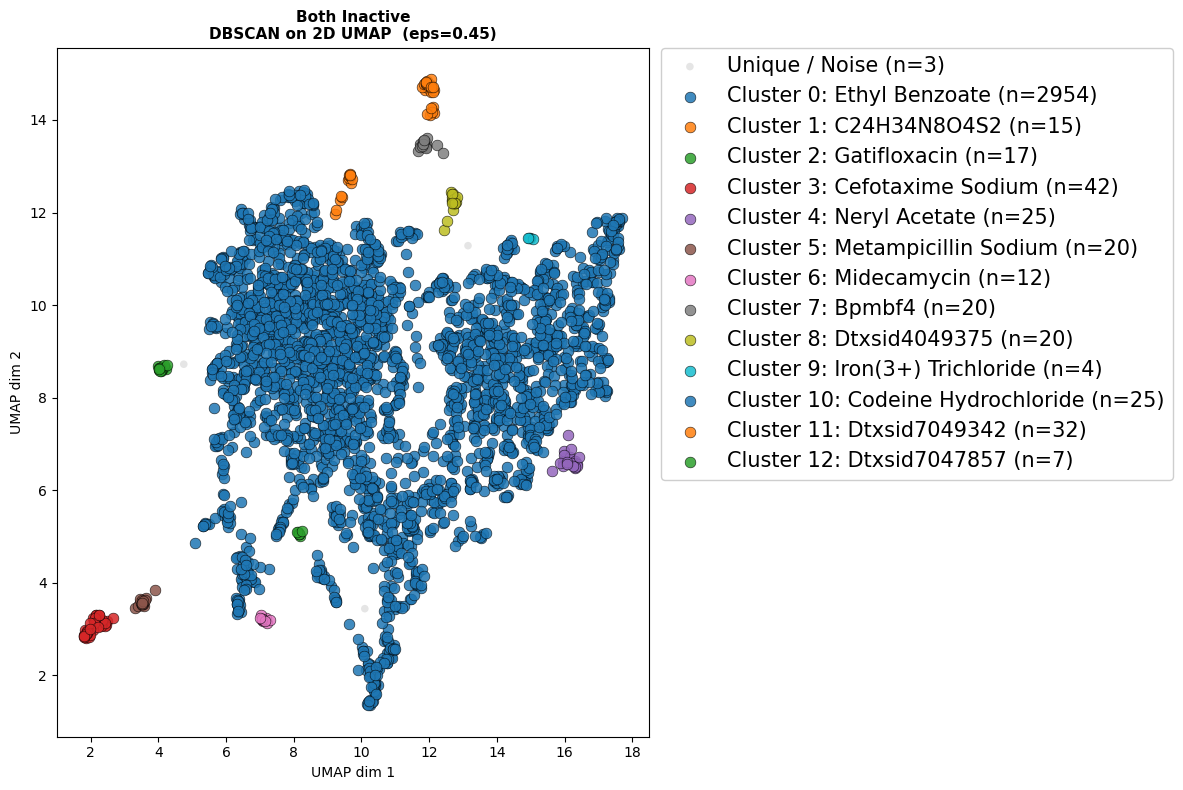

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/mito_viability_comparisons/umap_dbscan_mito_inactive_and_mito_viability_inactive.png



In [6]:
# ── EPS for DBSCAN in 2D UMAP space (Euclidean) ──────────────────────────────
# 1. Run this cell → inspect the k-NN distance plot per dataset.
# 2. Find the 'knee' (where the curve bends sharply).
# 3. Set EPS to that y-value and re-run.
# Typical range in 2D UMAP space: 0.3–0.7  (much smaller than Jaccard on FPs)
EPS         = 0.45   # <-- adjust after inspecting the k-NN plots below
MIN_SAMPLES = 3      # minimum cluster size

for label, fname in DATASETS:
    print('=' * 65)
    print(f'  {label}')
    print('=' * 65)

    # ── Load ──────────────────────────────────────────────────────────
    df = pd.read_csv(
        RESULTS + fname,
        usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
        low_memory=False, encoding=ENCODING
    ).dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates(subset='PUBCHEM_CID').reset_index(drop=True)
    print(f'Unique CIDs: {len(df)}')

    # ── Parse molecules + fingerprints ────────────────────────────────
    df['mol'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
        lambda s: Chem.MolFromSmiles(str(s)) if pd.notna(s) else None)
    df = df[df['mol'].notna()].reset_index(drop=True)
    fps_rdkit, fp_matrix = to_fp_matrix(df['mol'].tolist())
    df['fp'] = fps_rdkit
    N = len(df)
    print(f'Valid molecules: {N}')

    if N < 10:
        print('Too few molecules — skipping.\n')
        continue

    # ── UMAP: Jaccard on fingerprints → 2D ────────────────────────────
    emb = plot_umap(
        fp_matrix,
        labels   = [label] * N,
        title    = f'Chemical space — {label}  (N={N})',
        annotate = df['PUBCHEM_CID'],
    )
    df['umap_x'], df['umap_y'] = emb[:, 0], emb[:, 1]

    # ── k-NN distance plot on 2D UMAP coords (Euclidean) ─────────────
    # The knee = recommended EPS for DBSCAN in this 2D space.
    knn_eps_plot(emb, MIN_SAMPLES, f'k-NN distance — {label}')

    # ── DBSCAN on 2D UMAP (Euclidean) ────────────────────────────────
    db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(emb)
    df['cluster'] = db.labels_
    n_cl    = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    n_noise = (db.labels_ == -1).sum()
    print(f'\nDBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})'
          f'  →  {n_cl} clusters,  {n_noise} noise ({100*n_noise/N:.1f}%)')

    # ── Cluster size table ────────────────────────────────────────────
    comp = df.groupby('cluster').size().rename('Count').to_frame()
    comp.index = ['Noise' if i == -1 else f'Cluster {i}' for i in comp.index]
    print(comp.sort_values('Count', ascending=False).to_string())

    # ── MCS core + representative molecule per cluster ────────────────
    cl_names = draw_cluster_reps(df, title=label)

    # ── UMAP scatter coloured by cluster ─────────────────────────────
    umap_by_cluster(df, cl_names,
                    title=f'{label} — DBSCAN clusters\n'
                          f'(eps={EPS} on 2D UMAP, min_samples={MIN_SAMPLES})')

    # ── Save figure ───────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(12, 8))
    cmap = plt.cm.tab10
    noise_df = df[df['cluster'] == -1]
    if len(noise_df):
        ax.scatter(noise_df['umap_x'], noise_df['umap_y'], c='#cccccc',
                   s=30, alpha=0.5, edgecolors='none',
                   label=f'Unique / Noise (n={len(noise_df)})')
    for cl in sorted(c for c in df['cluster'].unique() if c != -1):
        sub  = df[df['cluster'] == cl]
        name = cl_names.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=60, edgecolors='black', linewidths=0.4, alpha=0.85,
                   label=f'Cluster {cl}: {name} (n={len(sub)})')
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=15,
              framealpha=0.95, borderaxespad=0)
    ax.set_title(f'{label}\nDBSCAN on 2D UMAP  (eps={EPS})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout()
    slug = fname.replace('.csv', '')
    out  = RESULTS + f'umap_dbscan_{slug}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {out}\n')
